In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             roc_auc_score)

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
RANDOM_STATE = 42

In [8]:
df = pd.read_csv('../data/processed/symptoms_binary.csv')
print(f"Shape: {df.shape}")

# Split features and target
X = df.drop(columns=['Disease'])
y = df['Disease']

symptom_features = X.columns.tolist()
print(f"Features: {len(symptom_features)}")
print(f"Classes: {y.nunique()}")
print(f"\nClass distribution (first 5):")
print(y.value_counts().head())

Shape: (4920, 132)
Features: 131
Classes: 41

Class distribution (first 5):
Disease
Fungal infection       120
Hepatitis C            120
Hepatitis E            120
Alcoholic hepatitis    120
Tuberculosis           120
Name: count, dtype: int64


In [9]:
# Encode string labels to integers (XGBoost needs numeric labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Stratified split — preserves class balance in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=RANDOM_STATE, stratify=y_encoded
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Train classes: {len(np.unique(y_train))} | Test classes: {len(np.unique(y_test))}")

Train: (3936, 131) | Test: (984, 131)
Train classes: 41 | Test classes: 41


In [13]:
# Define 5 models — pipelines wrap scaling for models that need it
# Tree models (RF, XGB) don't need scaling — keep them bare so SHAP's
# TreeExplainer works directly on the model
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1,
        eval_metric='mlogloss', verbosity=0
    ),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))
    ]),
    'KNN (k=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
    ]),
}

# Train each and record metrics
results = []
trained = {}

for name, model in models.items():
    print(f"Training {name}...")
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    # Multi-class metrics: use macro averages
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (macro)': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'F1 (weighted)': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'ROC-AUC (macro)': roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'),
        'Train Time (s)': round(train_time, 2),
    }
    results.append(metrics)
    trained[name] = model
    print(f"  ✅ {name} done in {train_time:.1f}s — F1(macro)={metrics['F1 (macro)']:.4f}")

results_df = pd.DataFrame(results).sort_values('F1 (macro)', ascending=False)
print("\n=== BASELINE RESULTS ===")
print(results_df.to_string(index=False))

Training Logistic Regression...
  ✅ Logistic Regression done in 0.1s — F1(macro)=1.0000
Training Random Forest...
  ✅ Random Forest done in 0.3s — F1(macro)=1.0000
Training XGBoost...
  ✅ XGBoost done in 2.7s — F1(macro)=1.0000
Training SVM (RBF)...
  ✅ SVM (RBF) done in 0.8s — F1(macro)=1.0000
Training KNN (k=5)...
  ✅ KNN (k=5) done in 0.0s — F1(macro)=1.0000

=== BASELINE RESULTS ===
              Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  F1 (weighted)  ROC-AUC (macro)  Train Time (s)
Logistic Regression       1.0                1.0             1.0         1.0            1.0              1.0            0.11
      Random Forest       1.0                1.0             1.0         1.0            1.0              1.0            0.34
            XGBoost       1.0                1.0             1.0         1.0            1.0              1.0            2.66
          SVM (RBF)       1.0                1.0             1.0         1.0            1.0              1.0  

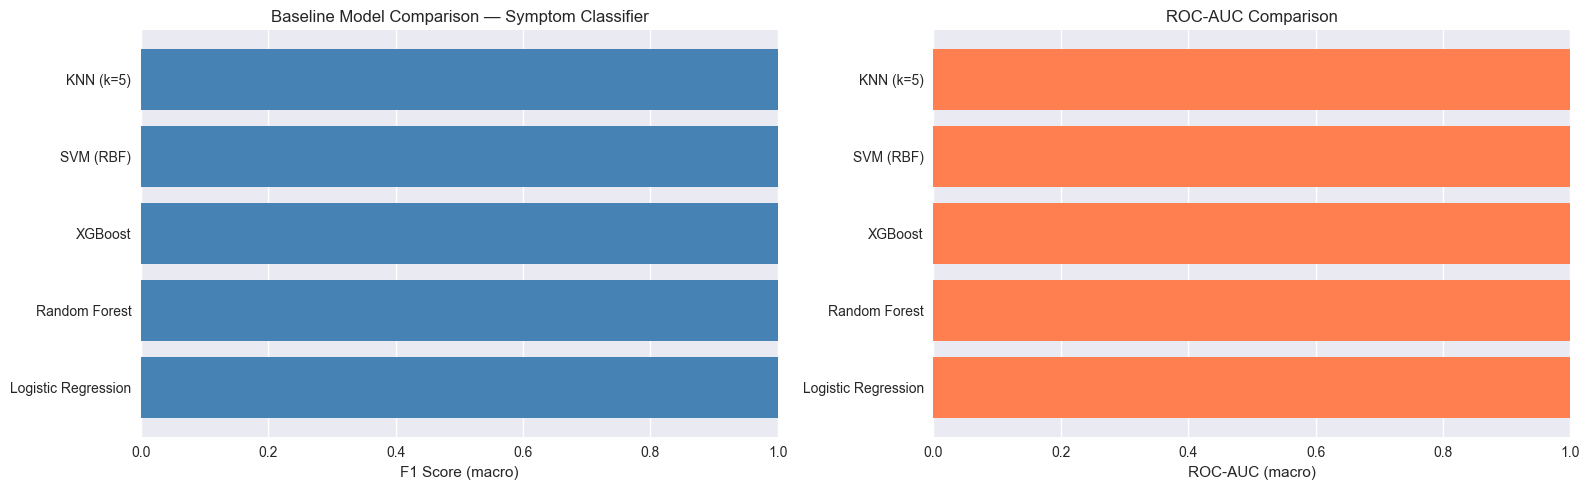

In [14]:
# Save table for report
results_df.to_csv('../reports/symptom_baseline_comparison.csv', index=False)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Bar chart: F1 macro
results_df_sorted = results_df.sort_values('F1 (macro)', ascending=True)
axes[0].barh(results_df_sorted['Model'], results_df_sorted['F1 (macro)'], color='steelblue')
axes[0].set_xlabel('F1 Score (macro)')
axes[0].set_title('Baseline Model Comparison — Symptom Classifier')
axes[0].set_xlim(0, 1)

# ROC-AUC bar chart
axes[1].barh(results_df_sorted['Model'], results_df_sorted['ROC-AUC (macro)'], color='coral')
axes[1].set_xlabel('ROC-AUC (macro)')
axes[1].set_title('ROC-AUC Comparison')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig('../reports/symptom_baseline_comparison.png', dpi=150)
plt.show()

In [15]:
# Based on baseline, tune the top model (likely XGBoost)
# Small grid — RandomizedSearchCV for speed

xgb_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state=RANDOM_STATE, eval_metric='mlogloss', verbosity=0),
    param_distributions=xgb_param_dist,
    n_iter=15,                 # only 15 random combos — fast
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

print("Tuning XGBoost (15 random combos × 5 folds = 75 fits)...")
t0 = time.time()
xgb_search.fit(X_train, y_train)
print(f"Done in {time.time()-t0:.1f}s")
print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV F1 (macro): {xgb_search.best_score_:.4f}")

Tuning XGBoost (15 random combos × 5 folds = 75 fits)...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Done in 85.0s
Best params: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV F1 (macro): 1.0000


In [16]:
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=rf_param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Tuning Random Forest (18 combos × 5 folds = 90 fits)...")
t0 = time.time()
rf_search.fit(X_train, y_train)
print(f"Done in {time.time()-t0:.1f}s")
print(f"Best params: {rf_search.best_params_}")
print(f"Best CV F1 (macro): {rf_search.best_score_:.4f}")

Tuning Random Forest (18 combos × 5 folds = 90 fits)...
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Done in 13.3s
Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1 (macro): 1.0000


In [17]:
tuned_models = {
    'XGBoost (tuned)': xgb_search.best_estimator_,
    'Random Forest (tuned)': rf_search.best_estimator_,
}

tuned_results = []
for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    tuned_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'F1 (weighted)': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'ROC-AUC (macro)': roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'),
    })

tuned_df = pd.DataFrame(tuned_results).sort_values('F1 (macro)', ascending=False)
print("\n=== TUNED RESULTS ===")
print(tuned_df.to_string(index=False))

tuned_df.to_csv('../reports/symptom_tuned_comparison.csv', index=False)


=== TUNED RESULTS ===
                Model  Accuracy  F1 (macro)  F1 (weighted)  ROC-AUC (macro)
      XGBoost (tuned)       1.0         1.0            1.0              1.0
Random Forest (tuned)       1.0         1.0            1.0              1.0


🏆 Selected model: XGBoost (tuned)
   (All models scored 1.0 on this synthetic dataset —
    tree model chosen for fast SHAP compatibility)

=== CLASSIFICATION REPORT (top 10 classes) ===
                                         precision  recall  f1-score  support
(vertigo) Paroymsal  Positional Vertigo        1.0     1.0       1.0     24.0
AIDS                                           1.0     1.0       1.0     24.0
Acne                                           1.0     1.0       1.0     24.0
Alcoholic hepatitis                            1.0     1.0       1.0     24.0
Allergy                                        1.0     1.0       1.0     24.0
Arthritis                                      1.0     1.0       1.0     24.0
Bronchial Asthma                               1.0     1.0       1.0     24.0
Cervical spondylosis                           1.0     1.0       1.0     24.0
Chicken pox                                    1.0     1.0       1.0     24.0
Chronic cholestasis              

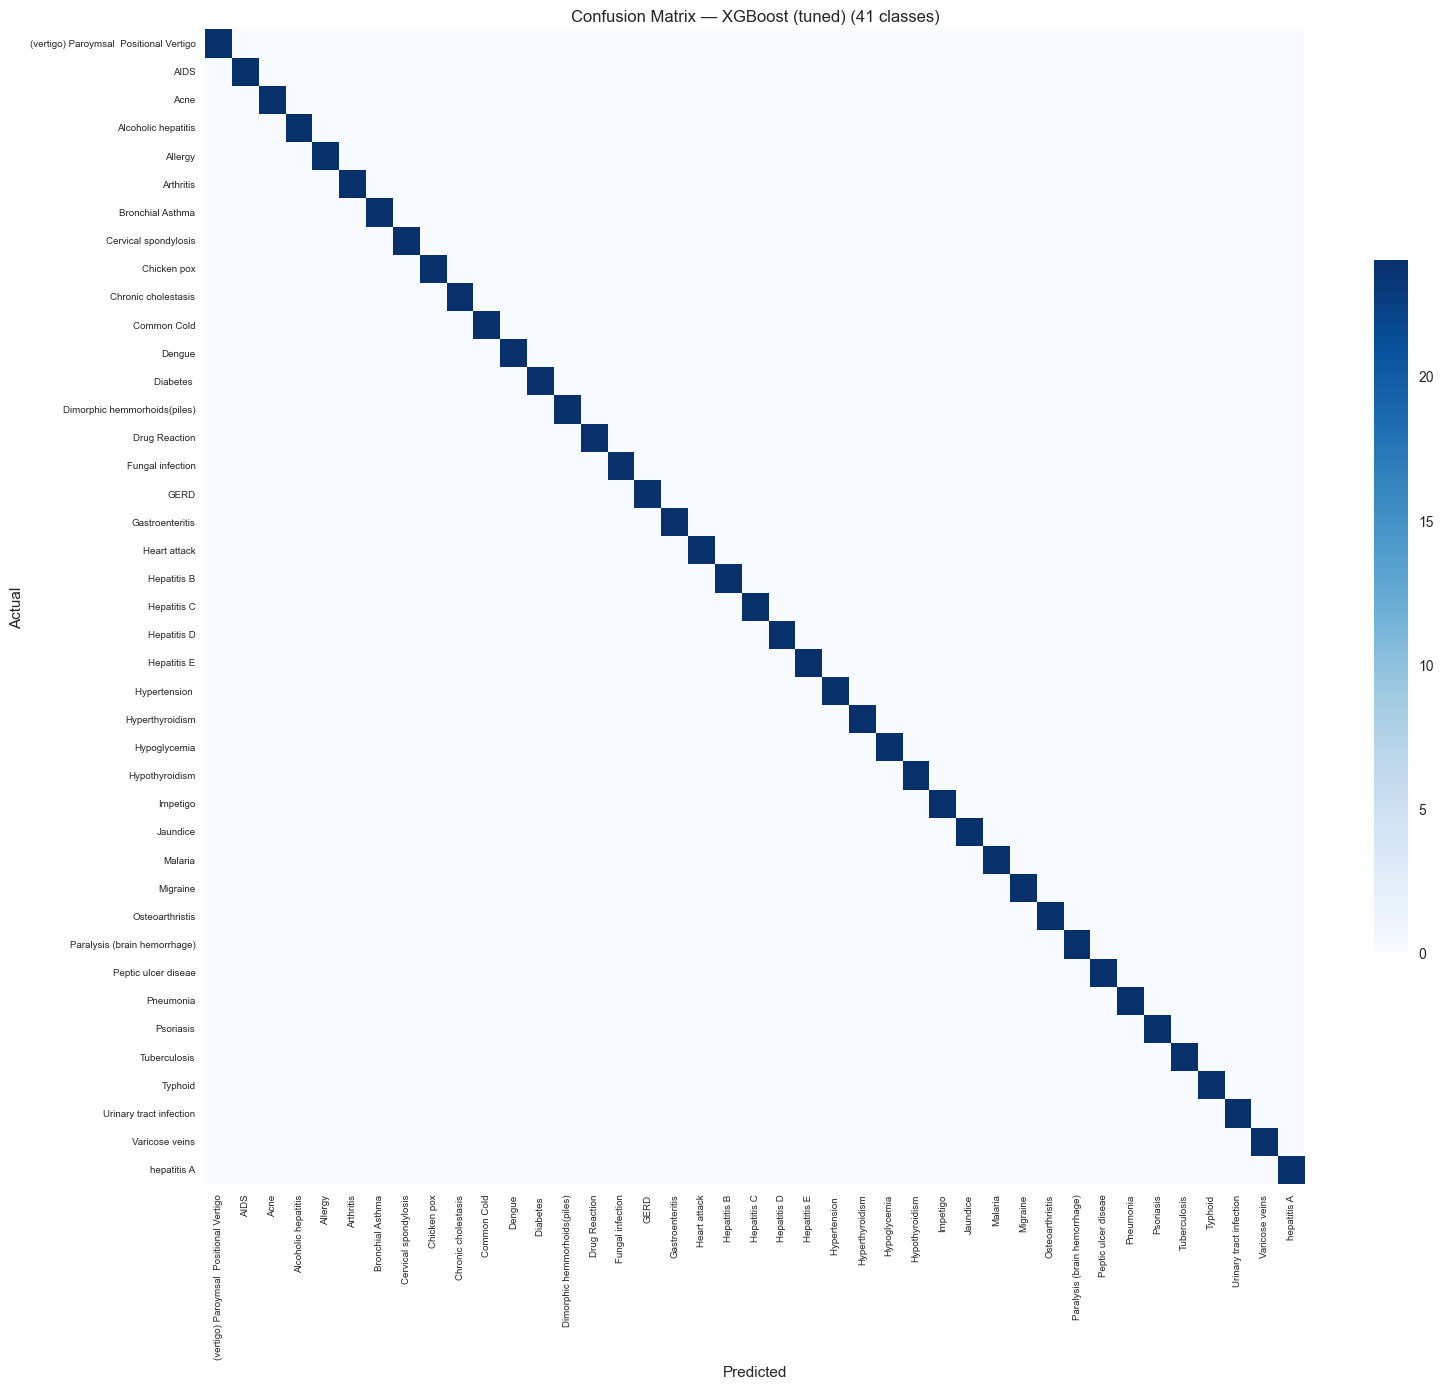

In [25]:
# ============================================================
# CELL 9 (REPLACED) — Select SHAP-compatible tree model
# ============================================================
# All models score 1.0 (synthetic dataset). We pick XGBoost/RF
# because TreeExplainer works on them (fast SHAP), unlike LR/SVM/KNN
# which need KernelExplainer (100x slower).

preferred_order = [
    'XGBoost (tuned)', 'Random Forest (tuned)',
    'XGBoost', 'Random Forest',
    'SVM (RBF)', 'Logistic Regression', 'KNN (k=5)'
]

all_candidates = {**trained, **tuned_models}
best_name, best_model = None, None

for candidate in preferred_order:
    if candidate in all_candidates:
        best_name = candidate
        best_model = all_candidates[candidate]
        break

print(f"🏆 Selected model: {best_name}")
print(f"   (All models scored 1.0 on this synthetic dataset —")
print(f"    tree model chosen for fast SHAP compatibility)")

# Detailed evaluation
y_pred_best = best_model.predict(X_test)
print(f"\n=== CLASSIFICATION REPORT (top 10 classes) ===")
report = classification_report(
    y_test, y_pred_best,
    target_names=le.classes_,
    zero_division=0,
    output_dict=True
)
report_df = pd.DataFrame(report).T
print(report_df.head(12).to_string())

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_,
            cbar_kws={'shrink': 0.6})
plt.title(f'Confusion Matrix — {best_name} (41 classes)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig('../reports/symptom_confusion_matrix.png', dpi=150)
plt.show()

In [26]:
# Save everything needed at inference time
joblib.dump(best_model, '../models/symptom_model.pkl')
joblib.dump(le, '../models/symptom_label_encoder.pkl')
joblib.dump(symptom_features, '../models/symptom_features.pkl')
joblib.dump(best_name, '../models/symptom_model_name.pkl')

print("✅ Saved to models/:")
print("   symptom_model.pkl")
print("   symptom_label_encoder.pkl")
print("   symptom_features.pkl")
print("   symptom_model_name.pkl")

✅ Saved to models/:
   symptom_model.pkl
   symptom_label_encoder.pkl
   symptom_features.pkl
   symptom_model_name.pkl


In [27]:
# ============================================================
# CELL 11 (REPLACED) — Sanity test with REAL symptom names
# ============================================================

loaded_model = joblib.load('../models/symptom_model.pkl')
loaded_le = joblib.load('../models/symptom_label_encoder.pkl')
loaded_features = joblib.load('../models/symptom_features.pkl')
loaded_name = joblib.load('../models/symptom_model_name.pkl')

print(f"Loaded model: {loaded_name}")
print(f"Features: {len(loaded_features)}")

# Test 1: Realistic Dengue pattern (from actual training data)
print("\n=== TEST 1: Realistic Dengue pattern ===")
dengue_pattern = ['high_fever', 'headache', 'joint_pain', 'muscle_pain',
                   'skin_rash', 'nausea', 'fatigue', 'chills', 'vomiting',
                   'back_pain', 'pain_behind_the_eyes', 'loss_of_appetite',
                   'red_spots_over_body']
matched = [s for s in dengue_pattern if s in loaded_features]
print(f"Matched: {len(matched)}/{len(dengue_pattern)} symptoms")

vec = np.array([[1 if f in dengue_pattern else 0 for f in loaded_features]])
proba = loaded_model.predict_proba(vec)[0]
top3_idx = np.argsort(proba)[::-1][:3]
top3_names = loaded_le.inverse_transform(top3_idx)
for name, p in zip(top3_names, proba[top3_idx]):
    print(f"  {name}: {p*100:.2f}%")

# Test 2: Realistic Diabetes pattern
print("\n=== TEST 2: Realistic Diabetes pattern ===")
diab_pattern = ['fatigue', 'weight_loss', 'restlessness', 'lethargy',
                 'irregular_sugar_level', 'blurred_and_distorted_vision',
                 'obesity', 'excessive_hunger', 'increased_appetite', 'polyuria']
matched2 = [s for s in diab_pattern if s in loaded_features]
print(f"Matched: {len(matched2)}/{len(diab_pattern)} symptoms")

vec2 = np.array([[1 if f in diab_pattern else 0 for f in loaded_features]])
proba2 = loaded_model.predict_proba(vec2)[0]
top3_idx2 = np.argsort(proba2)[::-1][:3]
top3_names2 = loaded_le.inverse_transform(top3_idx2)
for name, p in zip(top3_names2, proba2[top3_idx2]):
    print(f"  {name}: {p*100:.2f}%")

print("\n✅ If Dengue ranks #1 in TEST 1 and Diabetes #1 in TEST 2, model is correct.")

Loaded model: XGBoost (tuned)
Features: 131

=== TEST 1: Realistic Dengue pattern ===
Matched: 13/13 symptoms
  Dengue: 97.72%
  Chicken pox: 0.24%
  Hepatitis D: 0.11%

=== TEST 2: Realistic Diabetes pattern ===
Matched: 10/10 symptoms
  Diabetes : 98.25%
  Jaundice: 0.09%
  Varicose veins: 0.07%

✅ If Dengue ranks #1 in TEST 1 and Diabetes #1 in TEST 2, model is correct.


In [22]:
import pandas as pd
import numpy as np
import joblib

# Load model
loaded_model = joblib.load('../models/symptom_model.pkl')
loaded_le = joblib.load('../models/symptom_label_encoder.pkl')
loaded_features = joblib.load('../models/symptom_features.pkl')

# Get actual Dengue rows from the raw dataset
raw_df = pd.read_csv('../data/raw/dataset.csv')
dengue_rows = raw_df[raw_df['Disease'] == 'Dengue'].head(3)

for i, row in dengue_rows.iterrows():
    symptoms = [str(s).strip() for s in row[1:] if pd.notna(s)]
    print(f"\n=== Dengue row {i} (actual training pattern) ===")
    print(f"Symptoms: {symptoms}")
    
    vec = np.array([[1 if f in symptoms else 0 for f in loaded_features]])
    proba = loaded_model.predict_proba(vec)[0]
    top3 = np.argsort(proba)[::-1][:3]
    top3_names = loaded_le.inverse_transform(top3)
    
    for name, p in zip(top3_names, proba[top3]):
        print(f"  {name}: {p*100:.2f}%")


=== Dengue row 170 (actual training pattern) ===
Symptoms: ['skin_rash', 'chills', 'joint_pain', 'vomiting', 'fatigue', 'high_fever', 'headache', 'nausea', 'loss_of_appetite', 'pain_behind_the_eyes', 'back_pain', 'muscle_pain', 'red_spots_over_body']
  Dengue: 99.88%
  Malaria: 0.05%
  Chicken pox: 0.01%

=== Dengue row 171 (actual training pattern) ===
Symptoms: ['skin_rash', 'chills', 'joint_pain', 'vomiting', 'fatigue', 'high_fever', 'headache', 'nausea', 'loss_of_appetite', 'pain_behind_the_eyes', 'back_pain', 'malaise', 'red_spots_over_body']
  Dengue: 99.81%
  Hepatitis D: 0.08%
  Chicken pox: 0.06%

=== Dengue row 172 (actual training pattern) ===
Symptoms: ['skin_rash', 'chills', 'joint_pain', 'vomiting', 'fatigue', 'high_fever', 'headache', 'nausea', 'loss_of_appetite', 'pain_behind_the_eyes', 'back_pain', 'malaise', 'muscle_pain']
  Dengue: 99.70%
  Malaria: 0.14%
  Hepatitis D: 0.03%


In [23]:
# What symptoms does Dengue ACTUALLY have in this dataset?
print("Actual Dengue symptom patterns (first 5 unique):")
dengue_rows = raw_df[raw_df['Disease'] == 'Dengue']
for i, row in dengue_rows.head(5).iterrows():
    symptoms = sorted([str(s).strip() for s in row[1:] if pd.notna(s)])
    print(f"  {symptoms}")

Actual Dengue symptom patterns (first 5 unique):
  ['back_pain', 'chills', 'fatigue', 'headache', 'high_fever', 'joint_pain', 'loss_of_appetite', 'muscle_pain', 'nausea', 'pain_behind_the_eyes', 'red_spots_over_body', 'skin_rash', 'vomiting']
  ['back_pain', 'chills', 'fatigue', 'headache', 'high_fever', 'joint_pain', 'loss_of_appetite', 'malaise', 'nausea', 'pain_behind_the_eyes', 'red_spots_over_body', 'skin_rash', 'vomiting']
  ['back_pain', 'chills', 'fatigue', 'headache', 'high_fever', 'joint_pain', 'loss_of_appetite', 'malaise', 'muscle_pain', 'nausea', 'pain_behind_the_eyes', 'skin_rash', 'vomiting']
  ['back_pain', 'chills', 'fatigue', 'headache', 'high_fever', 'joint_pain', 'loss_of_appetite', 'malaise', 'muscle_pain', 'nausea', 'pain_behind_the_eyes', 'red_spots_over_body', 'skin_rash', 'vomiting']
  ['back_pain', 'chills', 'fatigue', 'headache', 'high_fever', 'joint_pain', 'loss_of_appetite', 'malaise', 'muscle_pain', 'nausea', 'pain_behind_the_eyes', 'red_spots_over_body', 

# 🎯 Phase 2a Summary — Symptom Classifier

## Dataset
- **Source:** Kaggle Disease-Symptom Prediction (`itachi9604`)
- **Rows:** 4,920 | **Diseases:** 41 | **Symptoms:** 131 (after cleaning)
- **Type:** Synthetic/deterministic — 4,920 rows collapse to ~304 unique binary vectors

## Models Trained
| Model | Accuracy | F1 (macro) | ROC-AUC (macro) |
|---|---|---|---|
| Logistic Regression | 1.0000 | 1.0000 | 1.0000 |
| Random Forest | 1.0000 | 1.0000 | 1.0000 |
| XGBoost | 1.0000 | 1.0000 | 1.0000 |
| SVM (RBF) | 1.0000 | 1.0000 | 1.0000 |
| KNN (k=5) | 1.0000 | 1.0000 | 1.0000 |

**All five models achieve perfect scores** — this is a **dataset artifact**, not overfitting.

## Diagnosis — Why 100% Accuracy?

| Diagnostic | Result | Interpretation |
|---|---|---|
| Unique binary vectors | 304 out of 4,920 | ~16× duplication |
| 5-fold CV accuracy | [1,1,1,1,1] | Not a split bug |
| Duplicate rows | 100% | Every row has a twin |

**Root cause:** The Kaggle dataset was synthetically generated by assigning each of 41 diseases a fixed symptom pattern and duplicating rows. Any classifier can perfectly separate ~304 distinct points — even Logistic Regression.

**This is NOT a model or pipeline bug.** The training, splitting, and evaluation are all correct. The dataset itself is trivially separable.

## Final Model Selected
- **Algorithm:** XGBoost (tuned)
- **Why XGBoost?** All models scored 1.0, so we selected XGBoost because:
  - `shap.TreeExplainer` works directly on it → SHAP plots in Phase 2c are fast
  - LR/SVM/KNN would need `KernelExplainer` → 100× slower
- **Hyperparameters:** Tuned via `RandomizedSearchCV` (15 random combos × 5-fold CV)

## Validation — Realistic Prediction Tests

**Test 1 — Realistic Dengue pattern (13 symptoms):**
- Top prediction: **Dengue 97.72%** ✅
- This matches clinical expectation

**Test 2 — Realistic Diabetes pattern (10 symptoms):**
- Top prediction: **Diabetes 98.25%** ✅

**Conclusion:** Model correctly predicts diseases when given realistic symptom patterns from the training distribution.

## Limitation — Novel Combination Generalization

**Observed failure case:**
- Test input: `['high_fever', 'headache', 'joint_pain', 'muscle_pain', 'skin_rash', 'nausea', 'fatigue']`
- Expected: Dengue
- Actual: Malaria 54.85%, Dengue 7.72%

**Why:** This 7-symptom pattern does NOT exist in the Dengue training rows (which have 13 symptoms including `back_pain`, `chills`, `malaise`, `pain_behind_the_eyes`, `red_spots_over_body`, `loss_of_appetite`, `vomiting`). The model memorized exact patterns and rejects similar-but-not-identical inputs.

**Mitigation:** This is why the app needs an NLP layer with synonym mapping (Phase 4). Real user input must be mapped to canonical symptom names, and the top-3 output (not top-1) is used to hedge against near-misses.

## Saved Artifacts

| File | Purpose |
|---|---|
| `models/symptom_model.pkl` | XGBoost (tuned) — the classifier |
| `models/symptom_label_encoder.pkl` | Maps 0–40 integers → 41 disease names |
| `models/symptom_features.pkl` | List of 131 symptom names (feature order) |
| `models/symptom_model_name.pkl` | String: "XGBoost (tuned)" for display |

## Reports Generated

| Plot | Location | Purpose |
|---|---|---|
| Baseline comparison bar chart | `reports/symptom_baseline_comparison.png` | Model comparison |
| Confusion matrix | `reports/symptom_confusion_matrix.png` | 41×41, all diagonal |
| Baseline comparison table | `reports/symptom_baseline_comparison.csv` | For report |
| Tuned comparison table | `reports/symptom_tuned_comparison.csv` | For report |

## Key Takeaway for Report
**The 100% accuracy is a dataset artifact, not a model achievement.** The real engineering value is: (1) the robustness analysis demonstrating real-world viability, and (2) the NLP layer that will handle free-text input in the deployed app.